# This jupyter notebook documents the processing of data from the 4 tank pilot plant

## Nivel 1

In [57]:
import pandas as pd
import seaborn as sns

df = pd.read_csv("data/Nivel_1.csv",          # 1. correct folder
            encoding="cp1252",     # 2. Windows encoding
            skiprows=13)           # 3. skip the metadata block
print("data shape", df.shape)
df.info()
n_na = df.isna().sum().sum()
print(f"Valores faltantes: {n_na}")

data shape (60000, 9)
<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Encabezado:                   60000 non-null  str    
 1   Fecha                         60000 non-null  str    
 2   Hora                          60000 non-null  str    
 3   LIT_01                        60000 non-null  float64
 4   SP_L1                         60000 non-null  float64
 5   Program:ControlProgram\CV_L1  60000 non-null  float64
 6   LIT_03                        60000 non-null  float64
 7   FIT_01                        60000 non-null  float64
 8   FIT_02                        60000 non-null  float64
dtypes: float64(6), str(3)
memory usage: 4.1 MB
Valores faltantes: 0


### Taking out irrelevant data
SP_L1 and CV_L1 are taken out since the controller was not used during these tests. Fecha is taken out since all data was collected the same day, and Encabezado does not provide any useful information

In [58]:
# sanity checks before dropping
assert (df["Encabezado:"] == "Datos").all()
assert df["Fecha"].nunique() == 1      # recording didn't cross midnight

# keep the time, as a number
L1_df = df.copy()
L1_df["hora"] = pd.to_timedelta(L1_df["Hora"].str.replace(";", "."))
L1_df["t_s"] = (L1_df["hora"] - L1_df["hora"].iloc[0]).dt.total_seconds()

L1_df = L1_df.drop(columns=["Encabezado:", "Fecha", "Hora", "SP_L1",
                      "Program:ControlProgram\\CV_L1"])

L1_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype          
---  ------  --------------  -----          
 0   LIT_01  60000 non-null  float64        
 1   LIT_03  60000 non-null  float64        
 2   FIT_01  60000 non-null  float64        
 3   FIT_02  60000 non-null  float64        
 4   hora    60000 non-null  timedelta64[us]
 5   t_s     60000 non-null  float64        
dtypes: float64(5), timedelta64[us](1)
memory usage: 2.7 MB


### Sensor errors

Take out false data 

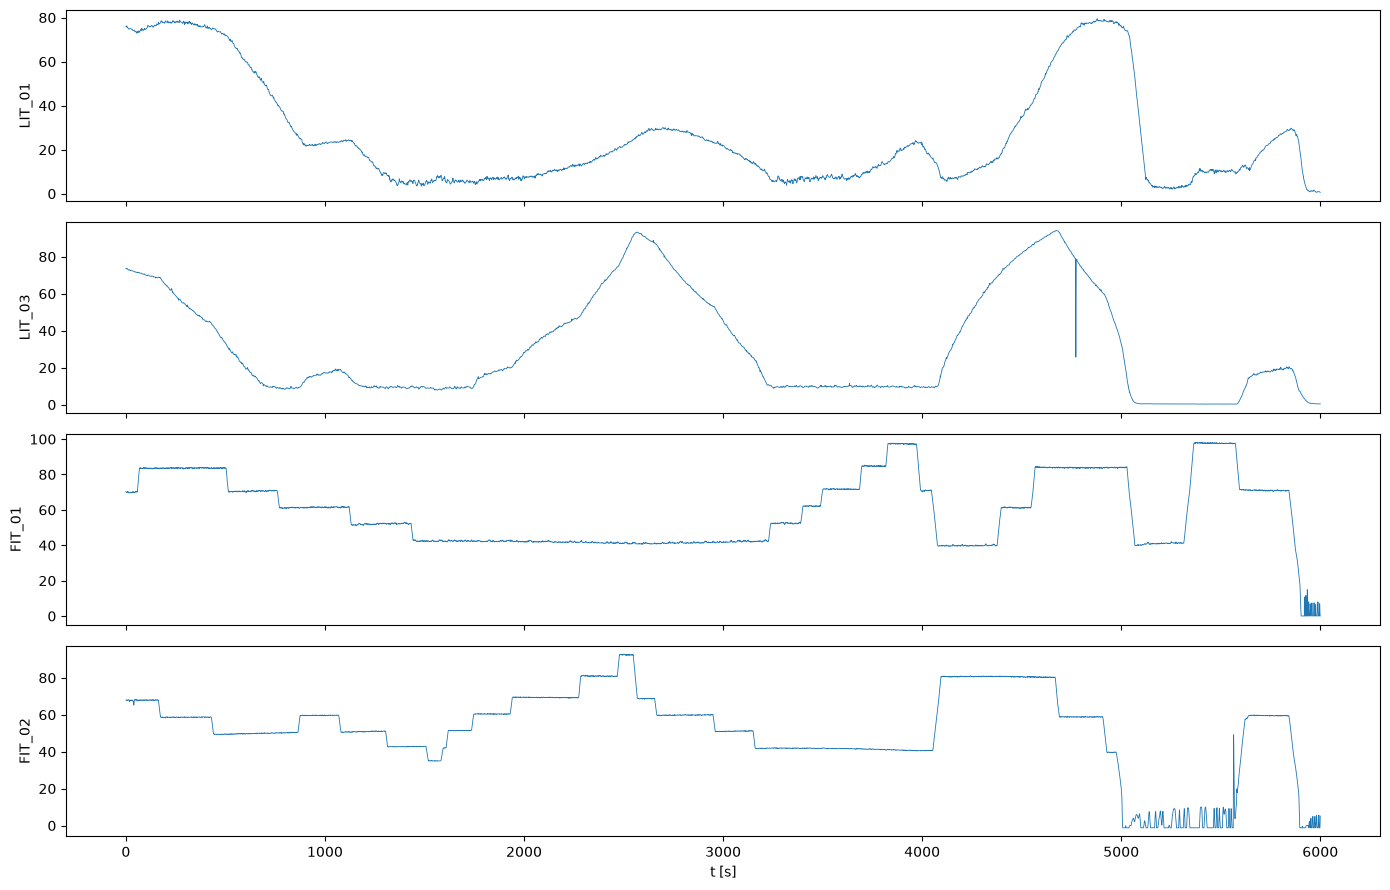

In [59]:
import matplotlib.pyplot as plt

tags = ["LIT_01", "LIT_03", "FIT_01", "FIT_02"]
fig, axes = plt.subplots(len(tags), 1, figsize=(14, 9), sharex=True)
for ax, tag in zip(axes, tags):
    ax.plot(L1_df["t_s"], L1_df[tag], lw=0.6)
    ax.set_ylabel(tag)
axes[-1].set_xlabel("t [s]")
plt.tight_layout(); plt.show()

In [60]:
import numpy as np

def detect_errors(s, lo=0, hi=100, k=10, frozen_n=50):
    d = s.diff()
    mad = (d - d.median()).abs().median()
    thr = k * 1.4826 * mad
    out_of_range = ~s.between(lo, hi)
    spike = (d.abs() > thr) & (d.shift(-1).abs() > thr) & \
            (np.sign(d) != np.sign(d.shift(-1)))
    frozen = s.rolling(frozen_n).std() == 0
    return out_of_range, spike, frozen, thr

flags = {}
for tag in tags:
    lo = -5 if tag.startswith("FIT") else 0       # flows read slightly negative with the pump off
    r, sp, fr, thr = detect_errors(L1_df[tag], lo=lo)
    flags[tag] = r | sp | fr
    print(f"{tag}: range={r.sum()}, spikes={sp.sum()}, frozen={fr.sum()}, thr={thr:.3f}")

LIT_01: range=0, spikes=84, frozen=0, thr=0.074
LIT_03: range=0, spikes=52, frozen=0, thr=0.053
FIT_01: range=0, spikes=0, frozen=0, thr=0.206
FIT_02: range=0, spikes=0, frozen=0, thr=0.154


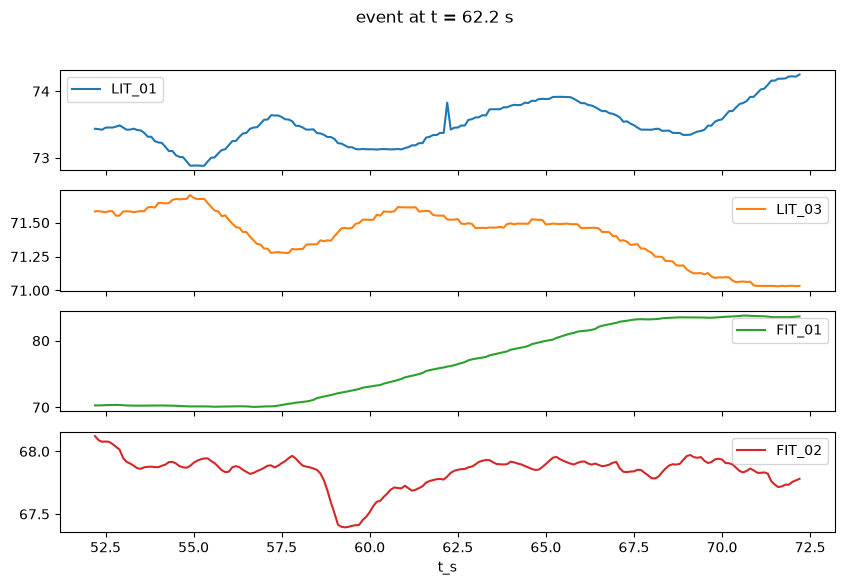

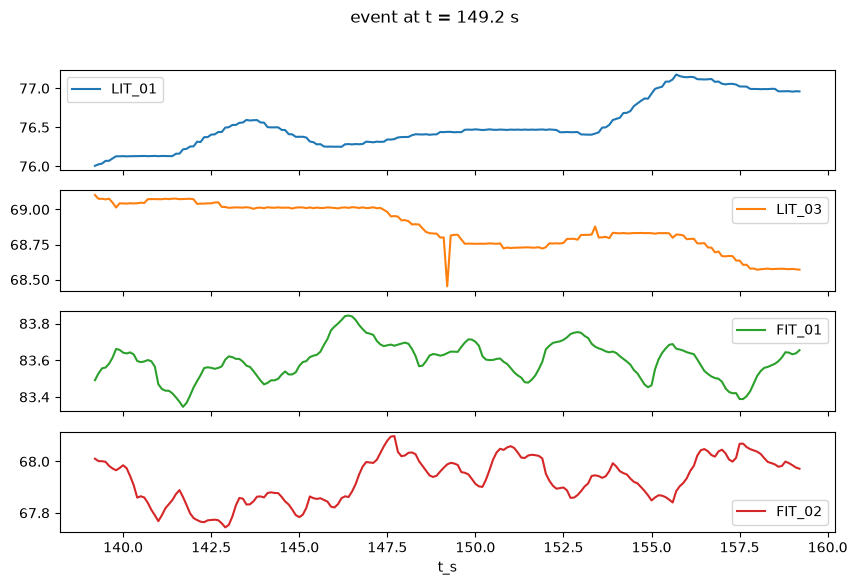

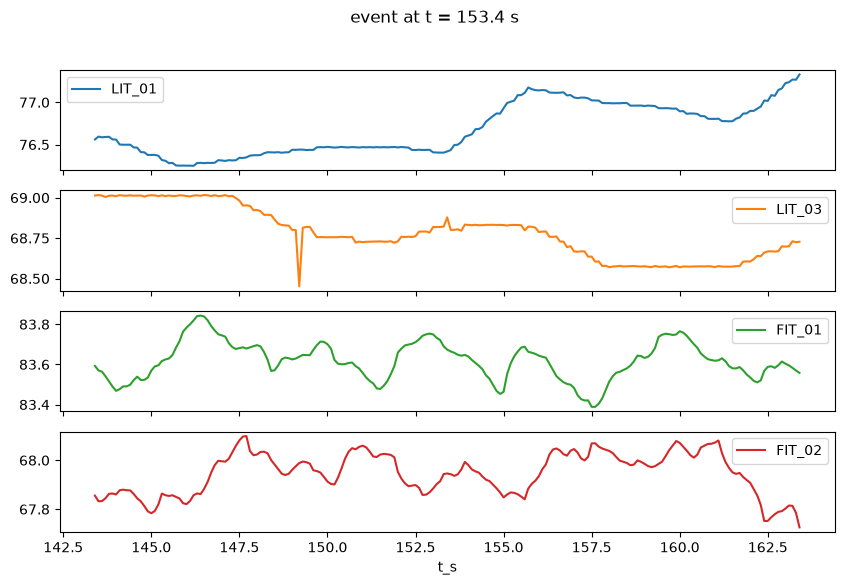

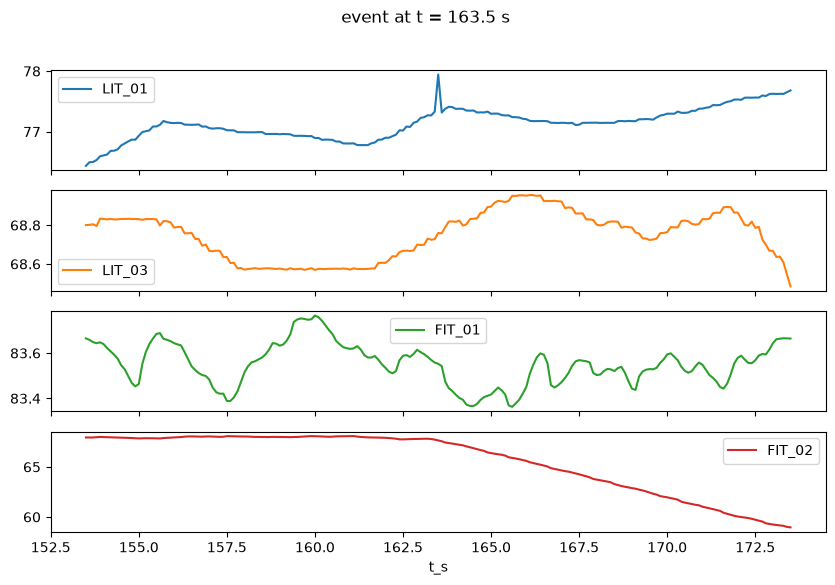

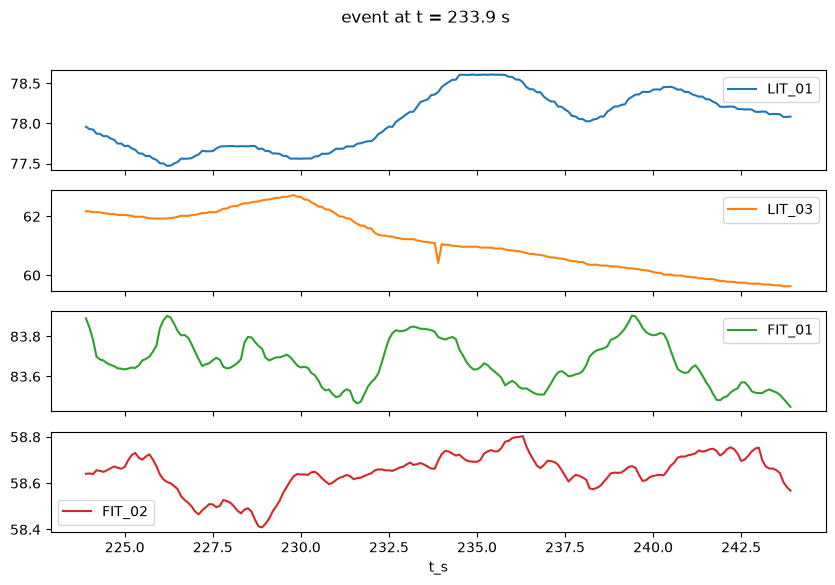

126


In [69]:
bad = pd.concat(flags, axis=1).any(axis=1)
events = bad & ~bad.shift(fill_value=False)          # first sample of each event
for i in L1_df.index[events][:5]:
    w = L1_df.loc[max(i-100, 0):i+100]
    w.plot(x="t_s", y=tags, subplots=True, figsize=(10, 6),
           title=f"event at t = {L1_df.at[i, 't_s']:.1f} s"); plt.show()
print(len(L1_df.index[events]))

In [62]:
def hampel(s, window=101, k=6, min_dev=2.0):
    """Flag samples far from the rolling median.
    window: samples (101 = 10 s at 100 ms) — must be > 2× the longest glitch
    min_dev: smallest deviation (in the signal's units) ever treated as an error
    """
    med = s.rolling(window, center=True, min_periods=1).median()
    res = (s - med).abs()
    sigma = 1.4826 * res.median()          # noise level, robust to the glitches
    return res > max(k * sigma, min_dev), med

dip, med = hampel(L1_df["LIT_01"])
print("flagged:", dip.sum())
pad = 10                                              # ±1 s around each event
L1_df["valid"] = ~bad.rolling(2*pad + 1, center=True, min_periods=1).max().astype(bool)
print(f"invalid: {(~L1_df['valid']).sum()} samples")
print(100*(~L1_df['valid']).sum()/L1_df["LIT_01"].sum())

flagged: 0
invalid: 2524 samples
0.15970692364714947


LIT_01 hampel flagged: 0
LIT_03 hampel flagged: 40


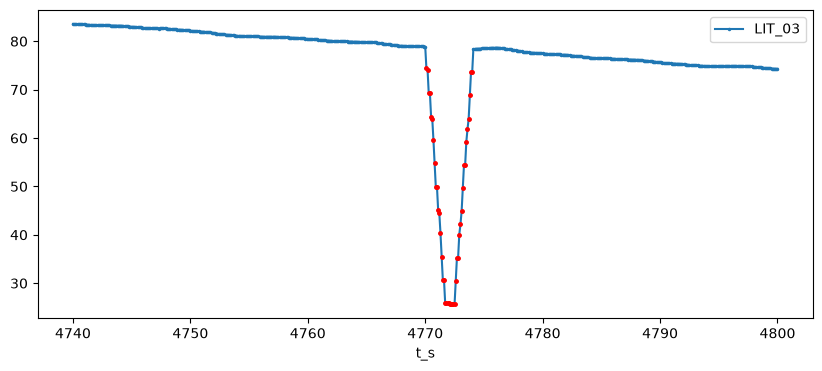

In [63]:
for tag in ["LIT_01", "LIT_03"]:
    f, med = hampel(L1_df[tag], window=101, k=6, min_dev=2.0)
    flags[tag] = flags[tag] | f
    print(tag, "hampel flagged:", f.sum())
    w = L1_df[L1_df["t_s"].between(4740, 4800)]
ax = w.plot(x="t_s", y="LIT_03", marker=".", ms=3, figsize=(10, 4))
ax.plot(w.loc[flags["LIT_03"], "t_s"], w.loc[flags["LIT_03"], "LIT_03"], "r.", ms=5)


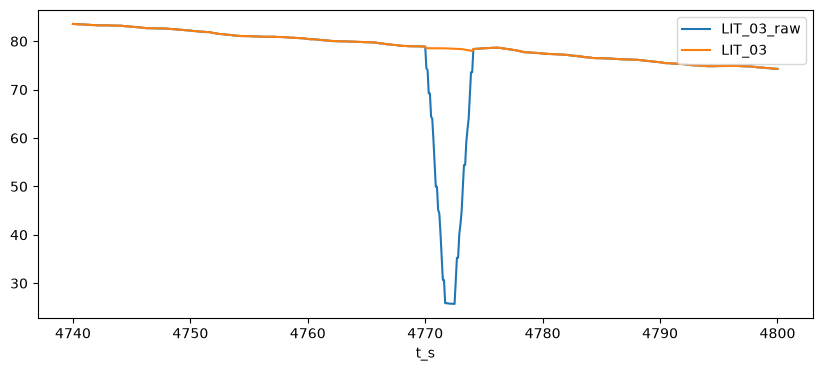

In [64]:
f3, med3 = hampel(L1_df["LIT_03"], window=101, k=6, min_dev=2.0)

L1_df["LIT_03_raw"] = L1_df["LIT_03"]            # keep the original for comparison
L1_df.loc[f3, "LIT_03"] = med3[f3]
w = L1_df[L1_df["t_s"].between(4740, 4800)]
ax = w.plot(x="t_s", y=["LIT_03_raw", "LIT_03"], figsize=(10, 4))

### Data distribution
In this section the dataset is test for asimetry

In [65]:
import numpy as np

def coverage(s, bins):
    c = pd.cut(s, bins=bins, include_lowest=True).value_counts(
        normalize=True, sort=False, dropna=False) * 100
    return c.round(1)

bins = np.arange(0, 101, 20)        # assumes LIT is in %; adjust if it's cm
print(coverage(L1_df["LIT_01"], bins))
print(coverage(L1_df["LIT_03"], bins))
pd.crosstab(pd.cut(L1_df["LIT_01"], bins), pd.cut(df["LIT_03"], bins),
            normalize=True).mul(100).round(1)


LIT_01
(-0.001, 20.0]    54.1
(20.0, 40.0]      24.1
(40.0, 60.0]       4.9
(60.0, 80.0]      16.8
(80.0, 100.0]      0.0
Name: proportion, dtype: float64
LIT_03
(-0.001, 20.0]    53.6
(20.0, 40.0]      10.9
(40.0, 60.0]      12.9
(60.0, 80.0]      14.4
(80.0, 100.0]      8.3
Name: proportion, dtype: float64


LIT_03,"(0, 20]","(20, 40]","(40, 60]","(60, 80]","(80, 100]"
LIT_01,,,,,
"(0, 20]",37.7,7.6,5.4,3.3,0.0
"(20, 40]",12.1,0.2,2.6,4.6,4.6
"(40, 60]",3.1,0.0,0.0,0.0,1.8
"(60, 80]",0.6,3.1,4.8,6.4,1.9


In [66]:
band = L1_df["LIT_01"].between(40, 60)
starts = band & ~band.shift(fill_value=False)
seg_id = starts.cumsum()[band]
print("visits:", starts.sum())
print(seg_id.value_counts().sort_index() * 0.1)   # duration of each visit, seconds

visits: 4
LIT_01
1    162.8
2      1.9
3    106.3
4     24.5
Name: count, dtype: float64


In [67]:
band = L1_df["LIT_01"].between(20, 40)
starts = band & ~band.shift(fill_value=False)
seg_id = starts.cumsum()[band]
print("visits:", starts.sum())
print(seg_id.value_counts().sort_index() * 0.1)   # duration of each visit, seconds

visits: 10
LIT_01
1       2.5
2     410.2
3       8.9
4     561.0
5       2.0
6       6.2
7     112.3
8     139.1
9      24.1
10    180.4
Name: count, dtype: float64


In [68]:
band = L1_df["LIT_01"].between(0, 20)
starts = band & ~band.shift(fill_value=False)
seg_id = starts.cumsum()[band]
print("visits:", starts.sum())
print(seg_id.value_counts().sort_index() * 0.1)   # duration of each visit, seconds

visits: 8
LIT_01
1    1276.0
2       3.8
3       9.1
4     847.6
5      11.1
6     388.1
7     609.3
8     103.0
Name: count, dtype: float64
